<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

湖南天雁机械股份有限公司（简称湖南天雁，股票代码 600698.SH）注册地在湖南省衡阳市石鼓区，成立于 1993 年 11 月，股票同年在上海证券交易所挂牌交易。公司的历史可以追溯到 1950 年，1991 年由几家工厂合并组建为湖南江雁机械厂，2003 年改制为有限责任公司，2012 年通过重大资产置换，把主营业务从摩托车零配件转到发动机零部件，2014 年更名为现在的名称。

公司属于央企体系。直接控股股东是辰致汽车科技集团有限公司，持有约 37% 的股份，辰致集团由中国长安汽车集团有限公司全资持有，实际控制人是国务院国有资产监督管理委员会。公司总股本约 10.69 亿股。

公司的主营业务是废气涡轮增压器、发动机进排气门和冷却风扇等发动机零部件的设计、开发、生产与销售。涡轮增压器是最主要的产品，按 2026 年中报，增压器收入约 2.56 亿元，占主营业务收入的八成以上，气门约占一成，其余是其他零部件。产品除了用在汽车上，也用于工程机械、农用机械、船用机械和高铁动车，客户包括长安汽车、潍柴、玉柴等整车厂和发动机厂。公司员工约 760 人。

公司拥有国家认定的企业技术中心和国家博士后科研工作站，是全国内燃机标准化技术委员会涡轮增压器工作组组长单位，2024 年入选国家专精特新重点“小巨人”企业。

# 第二部分：研究问题题目及其内涵介绍

我想弄清楚的问题是：湖南天雁这几年的经营状况如何，股价的表现有没有基本面支撑。

具体分成两个小问题。一是公司这几年是否盈利、收入有没有增长；二是股价这几年怎么走，与大盘相比是强是弱，和经营情况是否一致。

选这家公司，是因为我写会计论文时就研究过它。它的业绩长期不佳，股价却在个别年份大幅上涨，这个反差让我想进一步弄清楚。

# 第三部分：数据采集

In [1]:
# 先确认要用的几个库都在，缺了自动装（换台电脑打开时用得上）
import importlib.util, subprocess, sys
for pkg in ["tushare", "pandas", "numpy", "matplotlib"]:
    if importlib.util.find_spec(pkg) is None:
        print(f"缺少 {pkg}，正在安装，请稍等…")
        subprocess.run([sys.executable, "-m", "pip", "install", pkg])
print("要用的库都准备好了")

要用的库都准备好了


In [2]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

In [3]:
# 确认 token 已经设置好
import tushare as ts
print("tushare 版本：", ts.__version__)
print("token 状态：", "已设置" if ts.get_token() else "未设置")

tushare 版本： 1.4.29
token 状态： 已设置


下面用 tushare 采集公司的基本信息、股价、利润和财务指标，另外取上证指数作为大盘参照。

In [4]:
# ============ 第三部分：数据采集 ============
import os
import pandas as pd
import tushare as ts

# 如果前面老师的 token 代码还没运行过，这里自动补上，
# 保证单独点这一格也能取到数据
if "pro" not in dir():
    ts.set_token(token="5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521")
    pro = ts.pro_api()

pd.set_option("display.unicode.east_asian_width", True)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

CODE  = "600698.SH"        # 湖南天雁
BENCH = "000001.SH"        # 上证指数，用来当大盘的参照
START, END = "20190101", "20261007"   # 股价区间
FIN_START  = "20180101"    # 财务数据多取一年，方便和上一年做对比
SAVE_DIR = "data"
os.makedirs(SAVE_DIR, exist_ok=True)

def fetch(name, fn, **kw):
    """调用接口，打印一下取到多少行，同时检查有没有报错。"""
    df = fn(**kw)
    print(f"[{name}] 取到 {len(df)} 行 × {len(df.columns)} 列")
    return df

# 1. 公司基本信息
df_basic = fetch("公司信息 stock_basic", pro.stock_basic,
                 ts_code=CODE, fields="ts_code,name,area,industry,market,list_date,fullname")
df_basic.to_csv(f"{SAVE_DIR}/stock_basic.csv", index=False, encoding="utf-8-sig")

# 2. 每日股价
df_daily = fetch("日线行情 daily", pro.daily,
                 ts_code=CODE, start_date=START, end_date=END)
df_daily = df_daily.sort_values("trade_date").reset_index(drop=True)
df_daily.to_csv(f"{SAVE_DIR}/daily.csv", index=False, encoding="utf-8-sig")

# 3. 每日指标（市净率、总市值、换手率）
df_db = fetch("每日指标 daily_basic", pro.daily_basic,
              ts_code=CODE, start_date=START, end_date=END)
df_db = df_db.sort_values("trade_date").reset_index(drop=True)
df_db.to_csv(f"{SAVE_DIR}/daily_basic.csv", index=False, encoding="utf-8-sig")

# 4. 利润表（营业收入、净利润）
df_income = fetch("利润表 income", pro.income,
                  ts_code=CODE, start_date=FIN_START, end_date=END,
                  fields="ts_code,ann_date,end_date,report_type,total_revenue,"
                         "revenue,oper_cost,n_income,n_income_attr_p,basic_eps")
df_income.to_csv(f"{SAVE_DIR}/income.csv", index=False, encoding="utf-8-sig")

# 5. 财务指标（毛利率、ROE、扣非净利润）
df_fina = fetch("财务指标 fina_indicator", pro.fina_indicator,
                ts_code=CODE, start_date=FIN_START, end_date=END)
df_fina.to_csv(f"{SAVE_DIR}/fina_indicator.csv", index=False, encoding="utf-8-sig")

# 6. 上证指数（大盘参照）
df_index = fetch("上证指数 index_daily", pro.index_daily,
                 ts_code=BENCH, start_date=START, end_date=END)
df_index = df_index.sort_values("trade_date").reset_index(drop=True)
df_index.to_csv(f"{SAVE_DIR}/index_000001SH.csv", index=False, encoding="utf-8-sig")

print("\n数据已存到 ./data：", sorted(os.listdir(SAVE_DIR)))

# 最近 3 个交易日取到的行情
print("\n最近 3 个交易日：")
print(df_daily.tail(3)[["trade_date", "open", "close", "vol"]].to_string(index=False))

# 取到的公司基本信息
df_basic

[公司信息 stock_basic] 取到 1 行 × 7 列
[日线行情 daily] 取到 1877 行 × 11 列
[每日指标 daily_basic] 取到 1877 行 × 18 列
[利润表 income] 取到 49 行 × 10 列
[财务指标 fina_indicator] 取到 58 行 × 108 列
[上证指数 index_daily] 取到 1880 行 × 11 列

数据已存到 ./data： ['daily.csv', 'daily_basic.csv', 'fina_indicator.csv', 'fund.csv', 'hs300.csv', 'income.csv', 'index_000001SH.csv', 'maotai_fina.csv', 'maotai_price.csv', 'stock_basic.csv']

最近 3 个交易日：
trade_date  open  close       vol
  20260928  6.94   6.98 254443.19
  20260929  7.05   6.86 192646.59
  20260930  6.80   6.70 199415.87


,ts_code,name,area,industry,market,list_date,fullname
0,600698.SH,湖南天雁,湖南,汽车配件,主板,19931206,湖南天雁机械股份有限公司


# 第四部分：数据分析过程

In [5]:
# ============ 第四部分：数据分析 ============
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# 设置中文字体，不然图上中文会变成方块
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

# 这一格从 data/ 里读前面采集好的数据来用；本地还没有就先自己取一次，
# 所以单独点这一格也不会报错
import os
if not os.path.exists("data/income.csv"):
    import tushare as ts
    os.makedirs("data", exist_ok=True)
    p = ts.pro_api(ts.get_token() or "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521")
    p.income(ts_code="600698.SH", start_date="20180101", end_date="20261007").to_csv(
        "data/income.csv", index=False, encoding="utf-8-sig")
    p.fina_indicator(ts_code="600698.SH", start_date="20180101", end_date="20261007").to_csv(
        "data/fina_indicator.csv", index=False, encoding="utf-8-sig")
    p.daily(ts_code="600698.SH", start_date="20190101", end_date="20261007").sort_values(
        "trade_date").to_csv("data/daily.csv", index=False, encoding="utf-8-sig")

df_daily  = pd.read_csv("data/daily.csv", dtype={"trade_date": str})
df_income = pd.read_csv("data/income.csv", dtype={"ann_date": str, "end_date": str})
df_fina   = pd.read_csv("data/fina_indicator.csv", dtype={"end_date": str})

# 财务接口会同时返回一季报、中报和三季报，这里只保留年报（12 月 31 日那一期）
inc_ann = (df_income[df_income["end_date"].str.endswith("1231")]
           .drop_duplicates("end_date").sort_values("end_date").reset_index(drop=True))
fin_ann = (df_fina[df_fina["end_date"].str.endswith("1231")]
           .drop_duplicates("end_date").sort_values("end_date").reset_index(drop=True))

# 把营业收入、净利润、毛利率合并成一张表，单位换成好读的亿元和万元
fin = fin_ann[["end_date", "profit_dedt", "grossprofit_margin"]].copy()
fund = (inc_ann[["end_date", "total_revenue", "n_income_attr_p"]]
        .merge(fin, on="end_date", how="left").sort_values("end_date").reset_index(drop=True))
fund = fund[fund["end_date"].str[:4].astype(int) >= 2018].reset_index(drop=True)
fund = fund.dropna(subset=["profit_dedt"]).reset_index(drop=True)
fund["年份"] = fund["end_date"].str[:4]
fund["营业收入(亿元)"] = fund["total_revenue"] / 1e8
fund["归母净利润(万元)"] = fund["n_income_attr_p"] / 1e4
fund["扣非净利润(万元)"] = fund["profit_dedt"] / 1e4

# 存一份整理好的表，后面每张图都从它读，单独运行哪一格都不会报错
fund[["年份", "营业收入(亿元)", "归母净利润(万元)", "扣非净利润(万元)", "grossprofit_margin"]] \
    .to_csv("data/fund.csv", index=False, encoding="utf-8-sig")

print("股价区间：", df_daily.trade_date.min(), "→", df_daily.trade_date.max(),
      "共", len(df_daily), "个交易日")
print("年报期数：", len(fund), "期 →", list(fund["年份"]))

# 整理好的年报数据，后面三张图都用这张表
fund[["年份", "营业收入(亿元)", "归母净利润(万元)", "扣非净利润(万元)", "grossprofit_margin"]]

股价区间： 20190102 → 20260930 共 1877 个交易日
年报期数： 8 期 → ['2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']


,年份,营业收入(亿元),归母净利润(万元),扣非净利润(万元),grossprofit_margin
0,2018,4.691739,-8894.078819,-10110.020072,12.6854
1,2019,5.033028,1175.130425,-305.965964,21.0696
2,2020,6.420784,1020.240340,-756.722532,15.2529
3,2021,5.685364,876.504973,-325.228294,16.2886
4,2022,3.306028,-2779.907529,-3581.694103,13.5708
5,2023,4.877109,285.197836,-1234.729502,11.1275
6,2024,4.325056,411.740274,-4215.142124,7.6423
7,2025,5.159673,-3131.293493,-3670.391925,8.8768


下面从三个方面看这家公司这几年的变化：营业收入与利润、毛利率、股价与大盘的对比。

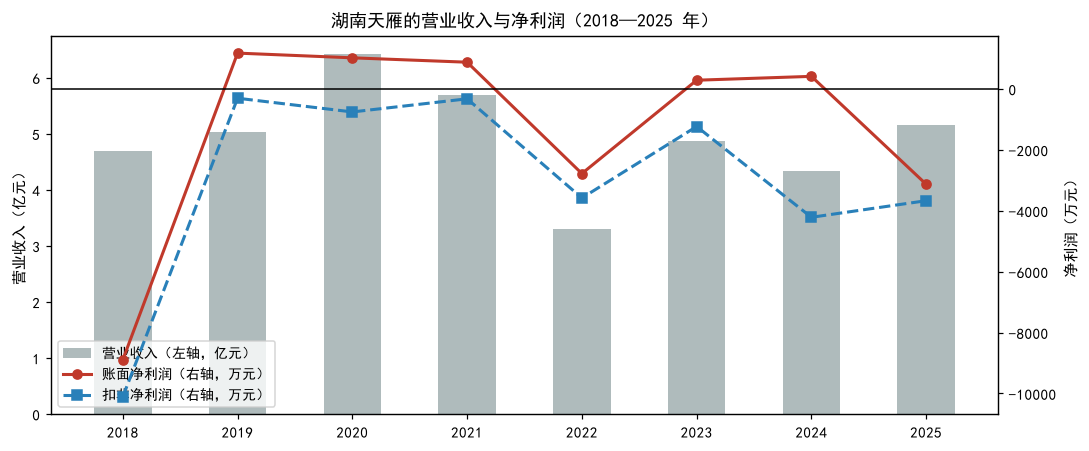

营业收入（亿元）： 4.69 → 5.03 → 6.42 → 5.69 → 3.31 → 4.88 → 4.33 → 5.16
扣非净利润（万元）： -10110 → -306 → -757 → -325 → -3582 → -1235 → -4215 → -3670
扣非净利润为负的年份：8 / 8 期
2024 年：账面净利润 412 万元，扣非后 -4215 万元


In [6]:
# 读数据（前面已经存到 data/ 目录；本地没有就先自己取一次，所以单独点这格也不会报错）
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
if not os.path.exists("data/fund.csv"):
    import tushare as ts
    os.makedirs("data", exist_ok=True)
    p = ts.pro_api(ts.get_token() or "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521")
    inc = p.income(ts_code="600698.SH", start_date="20180101", end_date="20261007")
    fin = p.fina_indicator(ts_code="600698.SH", start_date="20180101", end_date="20261007")
    f = (inc[inc.end_date.str.endswith("1231")].drop_duplicates("end_date")
         .merge(fin[fin.end_date.str.endswith("1231")].drop_duplicates("end_date"), on="end_date"))
    f = f[f.end_date.str[:4].astype(int) >= 2018].dropna(subset=["profit_dedt"])
    pd.DataFrame({"年份": f.end_date.str[:4], "营业收入(亿元)": f.total_revenue / 1e8,
                  "归母净利润(万元)": f.n_income_attr_p / 1e4,
                  "扣非净利润(万元)": f.profit_dedt / 1e4,
                  "grossprofit_margin": f.grossprofit_margin}).to_csv(
        "data/fund.csv", index=False, encoding="utf-8-sig")
fund = pd.read_csv("data/fund.csv")
fund["年份"] = fund["年份"].astype(str)

# 营业收入对比净利润
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(fund))
ax.bar(x, fund["营业收入(亿元)"], width=0.5, color="#95a5a6", alpha=0.75,
       label="营业收入（左轴，亿元）")
ax.set_ylabel("营业收入（亿元）")
ax.set_xticks(x); ax.set_xticklabels(fund["年份"])

ax2 = ax.twinx()
ax2.plot(x, fund["归母净利润(万元)"], "o-", color="#c0392b", lw=2,
         label="账面净利润（右轴，万元）")
ax2.plot(x, fund["扣非净利润(万元)"], "s--", color="#2980b9", lw=2,
         label="扣非净利润（右轴，万元）")
ax2.axhline(0, color="black", lw=1)
ax2.set_ylabel("净利润（万元）")

ax.set_title("湖南天雁的营业收入与净利润（2018—2025 年）", fontsize=12)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower left", fontsize=9)
ax.grid(False); ax2.grid(False)
plt.tight_layout(); plt.show()

print("营业收入（亿元）：", " → ".join(f"{v:.2f}" for v in fund["营业收入(亿元)"]))
print("扣非净利润（万元）：", " → ".join(f"{v:.0f}" for v in fund["扣非净利润(万元)"]))
print(f"扣非净利润为负的年份：{(fund['扣非净利润(万元)'] < 0).sum()} / {len(fund)} 期")
print(f"2024 年：账面净利润 {fund.loc[fund['年份']=='2024','归母净利润(万元)'].values[0]:.0f} 万元，"
      f"扣非后 {fund.loc[fund['年份']=='2024','扣非净利润(万元)'].values[0]:.0f} 万元")

图中灰色柱是各年的营业收入，两条折线分别是账面归母净利润和扣非归母净利润。营业收入在 4 亿至 6 亿元之间波动，2020 年最高为 6.42 亿元，2022 年最低为 3.31 亿元；2019 年是 5.03 亿元，2025 年是 5.16 亿元，七年下来整体没有增长。蓝色虚线一直在零以下，公司 2018 至 2025 年连续 8 年扣非净利润为负，说明主营业务一直在亏钱。扣非净利润是把政府补贴、资产处置这类一次性损益扣掉之后的利润，更能反映主营业务的真实盈利。红色实线偶尔会升到零以上，靠的正是这些一次性收入：2024 年账面盈利 412 万元，扣掉一次性损益后实际亏损 4,215 万元。

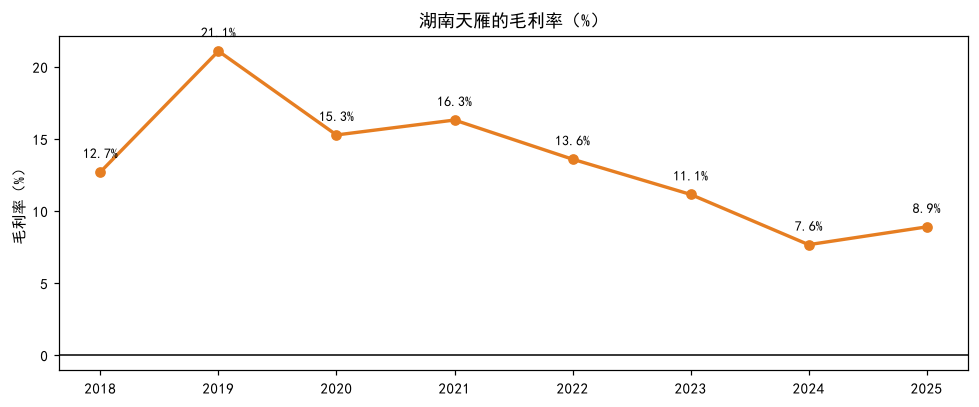

毛利率： 12.69% → 21.07% → 15.25% → 16.29% → 13.57% → 11.13% → 7.64% → 8.88%


In [7]:
# 读数据（前面已经存到 data/ 目录；本地没有就先自己取一次，所以单独点这格也不会报错）
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
if not os.path.exists("data/fund.csv"):
    import tushare as ts
    os.makedirs("data", exist_ok=True)
    p = ts.pro_api(ts.get_token() or "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521")
    inc = p.income(ts_code="600698.SH", start_date="20180101", end_date="20261007")
    fin = p.fina_indicator(ts_code="600698.SH", start_date="20180101", end_date="20261007")
    f = (inc[inc.end_date.str.endswith("1231")].drop_duplicates("end_date")
         .merge(fin[fin.end_date.str.endswith("1231")].drop_duplicates("end_date"), on="end_date"))
    f = f[f.end_date.str[:4].astype(int) >= 2018].dropna(subset=["profit_dedt"])
    pd.DataFrame({"年份": f.end_date.str[:4], "营业收入(亿元)": f.total_revenue / 1e8,
                  "归母净利润(万元)": f.n_income_attr_p / 1e4,
                  "扣非净利润(万元)": f.profit_dedt / 1e4,
                  "grossprofit_margin": f.grossprofit_margin}).to_csv(
        "data/fund.csv", index=False, encoding="utf-8-sig")
fund = pd.read_csv("data/fund.csv")
fund["年份"] = fund["年份"].astype(str)

# 毛利率走势
fy = fund.dropna(subset=["grossprofit_margin"]).copy()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(fy["年份"], fy["grossprofit_margin"], "o-", color="#e67e22", lw=2.2)
ax.axhline(0, color="black", lw=1)
for xx, yy in zip(fy["年份"], fy["grossprofit_margin"]):
    ax.annotate(f"{yy:.1f}%", (xx, yy), textcoords="offset points",
                xytext=(0, 9), ha="center", fontsize=9)
ax.set_title("湖南天雁的毛利率（%）", fontsize=12)
ax.set_ylabel("毛利率（%）")
plt.tight_layout(); plt.show()

print("毛利率：", " → ".join(f"{v:.2f}%" for v in fy["grossprofit_margin"]))

毛利率在 2019 年达到 21.07% 的高点后一路下滑，2024 年降到 7.64%，2025 年略回到 8.88%，六年间下降约 12 个百分点。在收入规模大体不变的情况下，留给公司的毛利越来越薄。上游钢材和有色金属涨价，公司难以把成本转嫁给下游整车厂，只能自行承担。

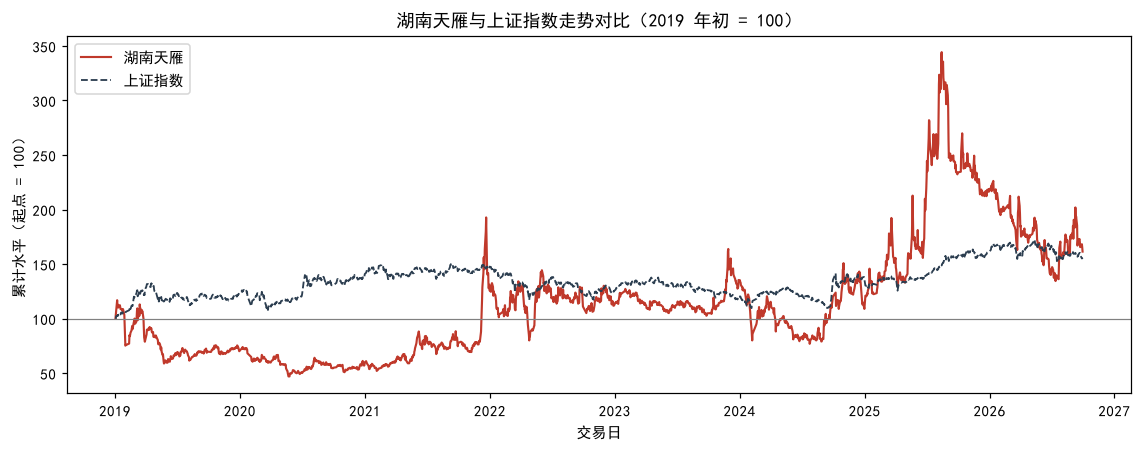

湖南天雁累计：+61.4%
上证指数累计：+55.9%


,公司年内涨跌幅%,上证年内涨跌幅%
年份,,
2019,-29.64,23.72
2020,-16.22,12.57
2021,106.32,3.91
2022,-10.06,-14.95
2023,18.07,-4.54
2024,-19.43,13.15
2025,86.39,21.65
2026,-26.62,-4.50


In [8]:
# 读数据（前面已经存到 data/ 目录；本地没有就先自己取一次，所以单独点这格也不会报错）
import os, pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
if not os.path.exists("data/daily.csv"):
    import tushare as ts
    os.makedirs("data", exist_ok=True)
    p = ts.pro_api(ts.get_token() or "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521")
    p.daily(ts_code="600698.SH", start_date="20190101", end_date="20261007").sort_values(
        "trade_date").to_csv("data/daily.csv", index=False, encoding="utf-8-sig")
    p.index_daily(ts_code="000001.SH", start_date="20190101", end_date="20261007").sort_values(
        "trade_date").to_csv("data/index_000001SH.csv", index=False, encoding="utf-8-sig")
df_daily = pd.read_csv("data/daily.csv", dtype={"trade_date": str})
df_index = pd.read_csv("data/index_000001SH.csv", dtype={"trade_date": str})

# 股价和上证指数对比
idx = df_index.copy()

fig, ax = plt.subplots(figsize=(10.5, 4.2))
ax.plot(pd.to_datetime(df_daily["trade_date"]),
        df_daily["close"] / df_daily["close"].iloc[0] * 100,
        color="#c0392b", lw=1.4, label="湖南天雁")
ax.plot(pd.to_datetime(idx["trade_date"]),
        idx["close"] / idx["close"].iloc[0] * 100,
        color="#2c3e50", lw=1.2, ls="--", label="上证指数")
ax.axhline(100, color="gray", lw=0.8)
ax.set_title("湖南天雁与上证指数走势对比（2019 年初 = 100）", fontsize=12)
ax.set_ylabel("累计水平（起点 = 100）")
ax.set_xlabel("交易日")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

print(f"湖南天雁累计：{(df_daily.close.iloc[-1]/df_daily.close.iloc[0]-1)*100:+.1f}%")
print(f"上证指数累计：{(idx.close.iloc[-1]/idx.close.iloc[0]-1)*100:+.1f}%")

# 每年的涨跌幅，按当年第一个交易日到最后一个交易日算
g1 = df_daily.assign(y=df_daily.trade_date.str[:4]).groupby("y")["close"]
g2 = idx.assign(y=idx.trade_date.str[:4]).groupby("y")["close"]
perf = pd.DataFrame({
    "公司年内涨跌幅%": (g1.last() / g1.first() - 1) * 100,
    "上证年内涨跌幅%": (g2.last() / g2.first() - 1) * 100,
}).round(2)
perf.index.name = "年份"
perf

图中红线是湖南天雁，黑色虚线是上证指数，两者都以 2019 年初为起点 100。到 2026 年 9 月，公司股价累计上涨 61.4%，上证指数上涨 55.9%，总涨幅接近。但从下面的年表看，公司的涨幅几乎全部来自 2021 年和 2025 年，这两年分别上涨 106% 和 86%，其余年份多数下跌或横盘。也就是说，它最终的涨幅与大盘相当，过程却比大盘颠簸得多。

# 第五部分：研究结论与经验总结

## 研究结论

结合前面三张图，开头提出的两个问题可以回答。

经营方面，公司的情况不太好。营业收入多年在 4 亿至 6 亿元之间波动，整体没有增长；毛利率从 21% 降到 9% 左右；扣非净利润连续 8 年为负。个别年份账面上是盈利的，靠的是政府补贴等一次性收入，不是主营业务赚来的。

股价方面，公司 2019 年初至 2026 年 9 月累计上涨 61.4%，同期上证指数上涨 55.9%，总涨幅接近；但涨幅几乎集中在 2021 年和 2025 年两次，其余年份多数下跌。这几年公司的经营并没有改善，所以我认为股价更多是受市场情绪和重组题材影响，和业绩并不匹配。

这次作业让我体会最深的一点是，判断一家公司赚不赚钱，不能只看净利润，还要看扣非净利润，否则容易把靠补贴撑起来的账面盈利误当成经营好转。

## 经验总结

这次作业我第一次用 tushare 取数据。做法是先设置一次 token，再用 pro = ts.pro_api() 建立接口，之后用 pro.daily、pro.income 这些方法把需要的数据取下来。
过程中踩了几个坑。一是股票代码后面要带 .SH 或 .SZ，日期要写成 20190101 这样的八位数字，不然取不到数据。二是财务接口一次会把一季报、中报、三季报和年报都返回，同一年有好几行，我只留年报那一行，不然同一年的数据就重复了。三是不同的表金额单位不一样，有的按元、有的按万元，我一开始放在一起算，结果差了一百倍，后来才发现。四是画图前要先设置中文字体，不然图上的中文会变成方框。
我原来以为净利润是正数就说明公司在赚钱，算完扣非净利润才知道两者可以差很多。选对指标，数据才能说明问题。